# Naive vs V5 vs V6: point-in-time backtest (2008-2017)

Compare the baseline `NaivePairsTradingModel`, V5, and V6 pair-specific realized-volatility variants on the same year-specific screened pairs for 2008-2017. V6 retains V5's signal, no-trade band, and saved year-specific exit-classifier weights. The percentile variants tune signed scales annually using only pre-test-year data; the no-overlays variant fixes both sizing scales at zero. Direct risk-target variants scale by `(trailing median hedged-pair risk / current forecast risk) ** gamma`, capped at 0.5-1.5; gamma=1, 0.5, and 0.25 are shown. Low-vol-boost variants only increase sizing when forecast pair risk is below its trailing median; gamma=0.5 and 1 are shown, plus gamma=1 with a 1.75 cap, a VIX-retuned variant, an annually tuned gamma variant, and a 30-day forecast-window variant. All V6 variants recalculate dynamic leverage from their own returns to target 8% annualized volatility with the same 4x cap. V5 and its weights are unchanged.

The notebook reports equal-weighted portfolio metrics and per-year returns/Sharpe for gross results and net results (5 bp transaction costs plus 50 bp annual borrow cost). Some early years have fewer than five passing pairs; the screen does not add pairs that fail its criteria.


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

PERIOD_START = 2008
PERIOD_END = 2017
RESULTS_DIR = Path("backtest_results")
NAIVE_DIR = RESULTS_DIR / "naive_vs_v5_2008_2017"
V5_DIR = RESULTS_DIR / "v5_extended_2008_2026"
MODEL_FILES = {
    "Gross": {
        "Naive": (NAIVE_DIR / "daily_results_0bps.csv", "naive_base"),
        "V5": (V5_DIR / "daily_results_gross.csv", "v5_ciaranMax_dynamic_vol"),
        "V6 (pair-vol signed)": (RESULTS_DIR / "v6_pair_vol_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (pair-vol VIX-style)": (RESULTS_DIR / "v6_pair_vol_025_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (no sizing overlays)": (RESULTS_DIR / "v6_no_vol_overlays_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (risk-target, gamma=1)": (RESULTS_DIR / "v6_pair_risk_target_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (risk-target, gamma=0.5)": (RESULTS_DIR / "v6_pair_risk_target_gamma_0p5_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (risk-target, gamma=0.25)": (RESULTS_DIR / "v6_pair_risk_target_gamma_0p25_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (low-vol boost)": (RESULTS_DIR / "v6_low_vol_boost_gamma_0p5_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (low-vol boost, gamma=1)": (RESULTS_DIR / "v6_low_vol_boost_gamma_1_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (low-vol boost, retrained exits)": (RESULTS_DIR / "v6_low_vol_boost_gamma_1_v6_exits_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (low-vol boost, gamma=1, cap=1.75)": (RESULTS_DIR / "v6_low_vol_boost_gamma_1_cap_1p75_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (low-vol boost, retuned VIX)": (RESULTS_DIR / "v6_low_vol_boost_gamma_1_retuned_vix_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (low-vol boost, tuned gamma)": (RESULTS_DIR / "v6_low_vol_boost_tuned_gamma_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
        "V6 (low-vol boost, 30-day risk)": (RESULTS_DIR / "v6_pair_low_vol_boost_gamma_1_vol30_rank504_2008_2017" / "daily_results_gross.csv", "v6_pair_vol"),
    },
    "Net (5 bp + 50 bp borrow)": {
        "Naive": (NAIVE_DIR / "daily_results_net_5bps_borrow_50.csv", "naive_base"),
        "V5": (V5_DIR / "daily_results_net_5bps_borrow_50.csv", "v5_ciaranMax_dynamic_vol"),
        "V6 (pair-vol signed)": (RESULTS_DIR / "v6_pair_vol_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (pair-vol VIX-style)": (RESULTS_DIR / "v6_pair_vol_025_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (no sizing overlays)": (RESULTS_DIR / "v6_no_vol_overlays_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (risk-target, gamma=1)": (RESULTS_DIR / "v6_pair_risk_target_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (risk-target, gamma=0.5)": (RESULTS_DIR / "v6_pair_risk_target_gamma_0p5_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (risk-target, gamma=0.25)": (RESULTS_DIR / "v6_pair_risk_target_gamma_0p25_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (low-vol boost)": (RESULTS_DIR / "v6_low_vol_boost_gamma_0p5_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (low-vol boost, gamma=1)": (RESULTS_DIR / "v6_low_vol_boost_gamma_1_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (low-vol boost, retrained exits)": (RESULTS_DIR / "v6_low_vol_boost_gamma_1_v6_exits_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (low-vol boost, gamma=1, cap=1.75)": (RESULTS_DIR / "v6_low_vol_boost_gamma_1_cap_1p75_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (low-vol boost, retuned VIX)": (RESULTS_DIR / "v6_low_vol_boost_gamma_1_retuned_vix_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (low-vol boost, tuned gamma)": (RESULTS_DIR / "v6_low_vol_boost_tuned_gamma_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
        "V6 (low-vol boost, 30-day risk)": (RESULTS_DIR / "v6_pair_low_vol_boost_gamma_1_vol30_rank504_2008_2017" / "daily_results_net_5bps_borrow_50.csv", "v6_pair_vol"),
    },
}


def load_model_daily(path, model_name):
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run the 2008?2017 backtests first.")
    daily = pd.read_csv(path, parse_dates=["date"], low_memory=False)
    daily = daily.loc[
        daily["model_name"].eq(model_name)
        & daily["date"].dt.year.between(PERIOD_START, PERIOD_END)
    ].copy()
    if daily.empty:
        raise ValueError(f"No {model_name} rows for {PERIOD_START}?{PERIOD_END} in {path}.")
    return daily


def portfolio_metrics(daily):
    returns = daily.groupby("date")["strategy_return"].mean().sort_index()
    wealth = (1 + returns).cumprod()
    volatility = returns.std(ddof=1)
    return {
        "observations": len(returns),
        "total_return": wealth.iloc[-1] - 1,
        "annualized_return": wealth.iloc[-1] ** (252 / len(returns)) - 1,
        "annualized_volatility": volatility * np.sqrt(252),
        "sharpe_ratio": returns.mean() / volatility * np.sqrt(252) if volatility > 0 else np.nan,
        "max_drawdown": (wealth / wealth.cummax() - 1).min(),
        "average_gross_exposure": daily["position_gross_exposure"].mean(),
        "average_daily_turnover": daily["turnover"].mean(),
    }, returns


portfolio_rows = []
yearly_rows = []
for cost_scenario, models in MODEL_FILES.items():
    for model_name, (path, file_model_name) in models.items():
        daily = load_model_daily(path, file_model_name)
        metrics, returns = portfolio_metrics(daily)
        portfolio_rows.append({"cost_scenario": cost_scenario, "model": model_name, **metrics})
        for year, year_returns in returns.groupby(returns.index.year):
            volatility = year_returns.std(ddof=1)
            yearly_rows.append({
                "cost_scenario": cost_scenario,
                "year": year,
                "model": model_name,
                "total_return": (1 + year_returns).prod() - 1,
                "sharpe_ratio": year_returns.mean() / volatility * np.sqrt(252) if volatility > 0 else np.nan,
            })

portfolio_comparison = pd.DataFrame(portfolio_rows).set_index(["cost_scenario", "model"])
yearly_comparison = pd.DataFrame(yearly_rows).pivot(
    index=["cost_scenario", "year"], columns="model", values=["total_return", "sharpe_ratio"]
)

print(f"Equal-weight portfolio comparison: {PERIOD_START}?{PERIOD_END}")
display(portfolio_comparison.round(4))
print("Yearly portfolio returns and Sharpe ratios")
display(yearly_comparison.round(3))

## V6 annual gross Sharpe and VIX

These charts use the consistent V6 low-vol-boost configuration with year-specific V5 exit weights. Annual Sharpe is computed from the equal-weighted daily portfolio returns; average VIX is the daily closing value over the same dates. The final year is partial.

,average_vix,gross_sharpe
year,,
2008,32.693,1.136
2009,31.479,0.526
2010,22.549,0.772
2011,24.203,0.580
2012,17.799,0.280
2013,14.230,0.953
2014,14.174,0.554
2015,16.674,1.130
2016,15.826,0.457


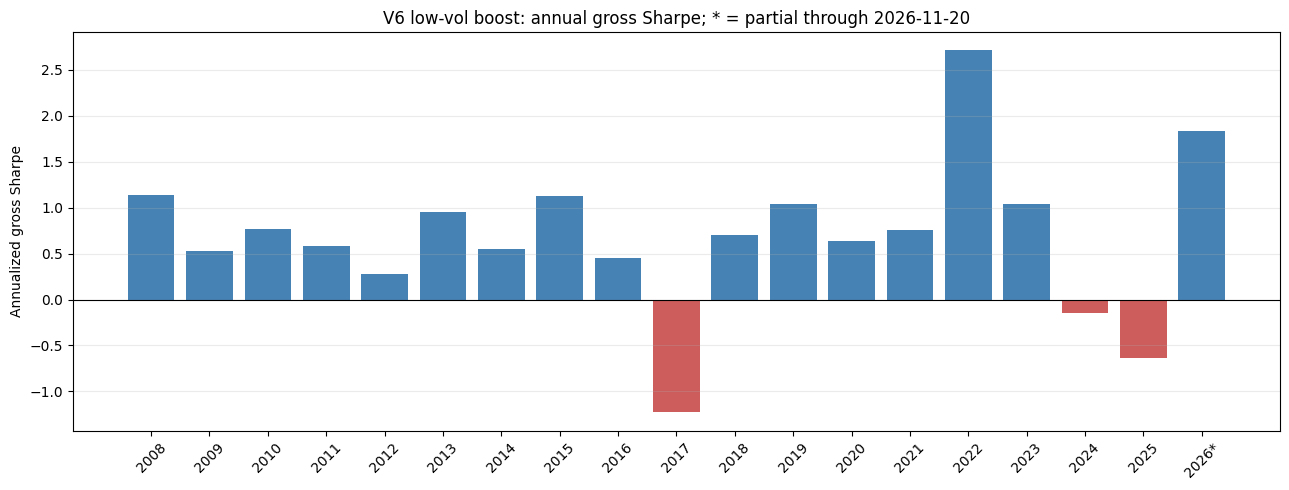

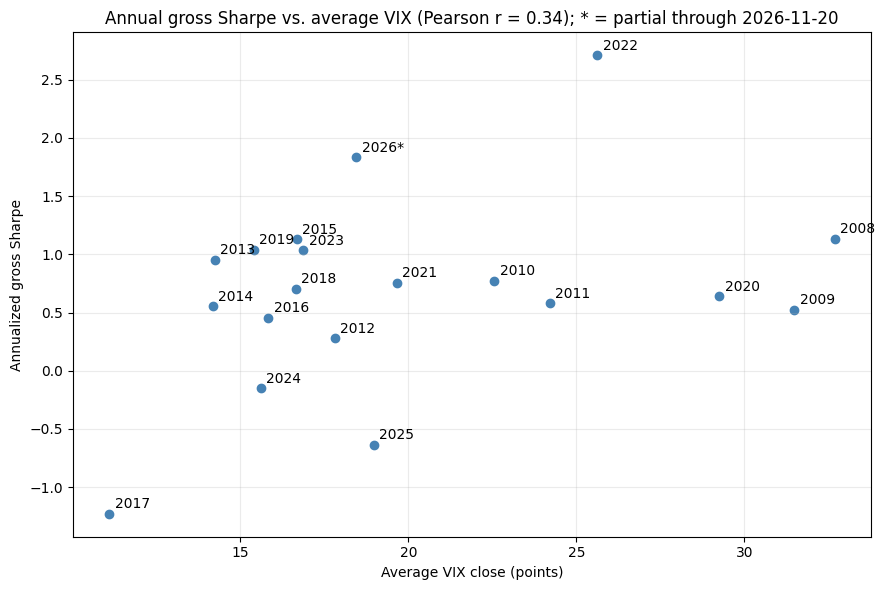

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = Path("backtest_results")
CHART_DIR = RESULTS_DIR / "v6_annual_sharpe_charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)
V6_ANNUAL_FILES = [
    RESULTS_DIR / "v6_low_vol_boost_gamma_1_2008_2017" / "daily_results_gross.csv",
    RESULTS_DIR / "v6_holdout_low_vol_boost_gamma_1_frozen_v5_exits_2018_2026" / "daily_results_gross.csv",
]
v6_daily = pd.concat(
    [pd.read_csv(path, parse_dates=["date"], low_memory=False) for path in V6_ANNUAL_FILES],
    ignore_index=True,
)
portfolio_returns_by_date = v6_daily.groupby("date")["strategy_return"].mean().sort_index()
vix_close = pd.read_csv(
    Path("data") / "universe_closes.csv",
    usecols=["date", "^VIX"],
    parse_dates=["date"],
).set_index("date")["^VIX"]
annual_daily = pd.DataFrame({
    "gross_return": portfolio_returns_by_date,
    "vix_close": vix_close.reindex(portfolio_returns_by_date.index),
})
if annual_daily["vix_close"].isna().any():
    raise ValueError("VIX closes are missing for some portfolio dates.")

year_groups = annual_daily.groupby(annual_daily.index.year)
annual_stats = year_groups.agg(average_vix=("vix_close", "mean"))
annual_stats["gross_sharpe"] = year_groups["gross_return"].apply(
    lambda returns: returns.mean() / returns.std(ddof=1) * np.sqrt(252)
    if returns.std(ddof=1) > 0 else np.nan
)
annual_stats.index.name = "year"
display(annual_stats.round(3))

last_date = annual_daily.index.max()
last_year = int(annual_stats.index.max())
year_labels = [f"{year}{'*' if year == last_year and last_date.month < 12 else ''}" for year in annual_stats.index]
partial_note = f"; * = partial through {last_date:%Y-%m-%d}" if last_date.month < 12 else ""

fig, ax = plt.subplots(figsize=(13, 5))
bar_colors = np.where(annual_stats["gross_sharpe"] >= 0, "steelblue", "indianred")
ax.bar(annual_stats.index, annual_stats["gross_sharpe"], color=bar_colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(annual_stats.index, year_labels, rotation=45)
ax.set_ylabel("Annualized gross Sharpe")
ax.set_title(f"V6 low-vol boost: annual gross Sharpe{partial_note}")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(CHART_DIR / "annual_gross_sharpe.png", dpi=160, bbox_inches="tight")
plt.show()

correlation = annual_stats["average_vix"].corr(annual_stats["gross_sharpe"])
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(annual_stats["average_vix"], annual_stats["gross_sharpe"], color="steelblue")
for year, row in annual_stats.iterrows():
    label = f"{year}{'*' if year == last_year and last_date.month < 12 else ''}"
    ax.annotate(label, (row["average_vix"], row["gross_sharpe"]), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Average VIX close (points)")
ax.set_ylabel("Annualized gross Sharpe")
ax.set_title(f"Annual gross Sharpe vs. average VIX (Pearson r = {correlation:.2f}){partial_note}")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(CHART_DIR / "sharpe_vs_average_vix.png", dpi=160, bbox_inches="tight")
plt.show()

### Annual Sharpe by year

![Annual gross Sharpe by year](backtest_results/v6_annual_sharpe_charts/annual_gross_sharpe.png)

### Annual Sharpe vs. average VIX

![Annual gross Sharpe versus average VIX](backtest_results/v6_annual_sharpe_charts/sharpe_vs_average_vix.png)